<a href="https://colab.research.google.com/github/guljahonabdusalomova/anime_faces/blob/main/anime_cdcgan_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML102 — Group Project
## Anime Face Generation with a Conditional Deep Convolutional GAN (cDCGAN)

**Team:** Oleg Kravchenko, Alexander Lim, Guljahon Abdusalamova

**Goal:** train a GAN that draws new anime faces, and lets the user **choose the hair colour** (black, brown, blonde, blue, pink, white).

**By the end of this notebook we will be able to:**

1. Prepare a labelled image dataset (one hair colour per image, balanced classes).
2. Build a **Generator** and a **Discriminator** with convolution layers (DCGAN).
3. Give the hair colour to both networks as a **condition** (one-hot vector).
4. Train the two networks **in turns** and watch their losses.
5. Generate new faces for any hair colour and save the model for deployment.

**Before you start:** in Google Colab go to **Runtime > Change runtime type** and select **GPU (T4)**. Run the cells **in order**, from top to bottom.

| Section | What happens |
|---|---|
| 1 | Setup |
| 2 | Settings |
| 3 | Where to save files (Google Drive) |
| 4 | Build the dataset (filter, balance, resize) |
| 5 | Dataset class, transforms and DataLoader |
| 6 | Look at the training images |
| 7 | The Generator |
| 8 | The Discriminator |
| 9 | Check shapes and parameters |
| 10 | Loss function and optimizers |
| 11 | The training loop |
| 12 | Loss curves |
| 13 | Generate faces for every hair colour |
| 14 | Save the model |
| 15 | Summary |

## 1. Setup

We import the libraries we need:

- `torch` and `torch.nn` to build and train the networks
- `torchvision.transforms` to prepare the images, `torchvision.utils` to draw a grid of images
- `pandas`, `numpy` and `PIL` to read and process the dataset
- `huggingface_hub` to read the dataset files from Hugging Face
- `matplotlib` for images and plots

We also fix the **random seed**, so every run gives similar results, and choose the **device** (GPU if available).

In [1]:
import os, io, re, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import make_grid


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cpu


## 2. Settings

All important numbers are in **one place**, so they are easy to change.

| Setting | Value | Why |
|---|---|---|
| `IMG_SIZE` | 64 | Standard size for DCGAN; 4x fewer pixels than 128, so training is much faster |
| `PER_CLASS` | 4700 | The same number of images for every colour, so the classes are **balanced** |
| `NOISE_DIM` | 100 | Length of the random noise vector `z` (the usual value for DCGAN) |
| `BATCH_SIZE` | 128 | Images per training step |
| `EPOCHS` | 25 | Full passes over the data (about 10–15 minutes on a T4 GPU) |
| `LR` | 0.0002 | Learning rate recommended in the DCGAN paper |
| `BETA1` | 0.5 | Adam momentum value recommended for GANs (the default 0.9 makes GAN training less stable) |

In [2]:
CLASSES = ["black", "brown", "blonde", "blue", "pink", "white"]   # our 6 hair colours
NUM_CLASSES = len(CLASSES)

IMG_SIZE = 64
PER_CLASS = 4700
NOISE_DIM = 100
BATCH_SIZE = 128
EPOCHS = 25
LR = 0.0002
BETA1 = 0.5

print("Classes:", CLASSES)
print("Total training images:", PER_CLASS * NUM_CLASSES)

Classes: ['black', 'brown', 'blonde', 'blue', 'pink', 'white']
Total training images: 28200


## 3. Where to save files

Colab **deletes** all files when the session ends. So we save the dataset and the trained model in **Google Drive**. Colab will ask for permission once.

If you don't want to use Drive, the files are saved in `/content` instead (but they disappear when the session ends).

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/anime_cdcgan"
except Exception as e:
    print("Google Drive not used:", e)
    SAVE_DIR = "./anime_cdcgan"

os.makedirs(SAVE_DIR, exist_ok=True)
print("Files will be saved in:", SAVE_DIR)

Mounted at /content/drive
Files will be saved in: /content/drive/MyDrive/anime_cdcgan


## 4. Build the dataset

**Source:** Danbooru Face Crops 128 on Hugging Face (anime face crops, 128 x 128, safe-for-work version). Each image has Danbooru **tags** such as `pink_hair smile solo`.

We read the 30 training files one by one and keep an image only if:

1. its rating is **`g`** (general = completely safe),
2. it has **exactly one** hair-colour tag and no pattern tag (`multicolored_hair`, `two-tone_hair`, ...),
3. that colour is one of our 6 classes,
4. we still need images of that colour (we stop at `PER_CLASS` per colour → **balanced classes**).

Every kept image is resized from 128 x 128 to **64 x 64** and stored as numbers (`uint8`, 0–255).

At the end we save everything in one file (`faces_64.npz`). **Next time, this cell just loads the file** (a few seconds instead of about 10 minutes).

In [4]:
HAIR_TAGS = ["black_hair", "brown_hair", "blonde_hair", "blue_hair", "pink_hair",
             "red_hair", "white_hair", "grey_hair", "silver_hair", "purple_hair",
             "green_hair", "orange_hair", "aqua_hair", "light_brown_hair",
             "light_blue_hair", "light_purple_hair", "dark_blue_hair"]
PATTERN_TAGS = ["multicolored_hair", "two-tone_hair", "gradient_hair", "streaked_hair"]


def get_hair_class(tag_string):
    # Returns the class number (0-5) or None if the image is not usable
    tags = set(str(tag_string).split())
    if any(p in tags for p in PATTERN_TAGS):
        return None                                   # two or more colours -> skip
    found = [t for t in HAIR_TAGS if t in tags]
    if len(found) != 1:
        return None                                   # no colour or many colours -> skip
    colour = found[0].replace("_hair", "")
    return CLASSES.index(colour) if colour in CLASSES else None

In [5]:
DATA_FILE = os.path.join(SAVE_DIR, "faces_64.npz")

if os.path.exists(DATA_FILE):
    saved = np.load(DATA_FILE)
    images, labels = saved["images"], saved["labels"]
    print("Loaded saved dataset from Drive.")
else:
    from huggingface_hub import HfFileSystem
    fs = HfFileSystem()
    files = sorted(fs.glob("datasets/nikhilr01/danbooru-face-crops-128/data/train-*.parquet"))

    images, labels = [], []
    counts = [0] * NUM_CLASSES
    start = time.time()

    for i, f in enumerate(files):
        df = pd.read_parquet("hf://" + f, columns=["rating", "tag_string_general", "image"])
        df = df[df["rating"] == "g"]                       # 1. safe images only

        for tag_string, img in zip(df["tag_string_general"], df["image"]):
            c = get_hair_class(tag_string)                 # 2. + 3. one of our colours
            if c is None or counts[c] >= PER_CLASS:        # 4. class already full
                continue
            picture = Image.open(io.BytesIO(img["bytes"])).convert("RGB")
            picture = picture.resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
            images.append(np.array(picture))
            labels.append(c)
            counts[c] += 1

        print(f"file {i + 1}/{len(files)} | images per class: {counts} | {time.time() - start:.0f}s")
        if min(counts) >= PER_CLASS:                       # every class is full -> stop early
            break

    images = np.stack(images).astype(np.uint8)             # shape (N, 64, 64, 3)
    labels = np.array(labels, dtype=np.int64)              # shape (N,)
    np.savez_compressed(DATA_FILE, images=images, labels=labels)
    print("Saved dataset to", DATA_FILE)

print("Images:", images.shape, "| Labels:", labels.shape)

file 1/30 | images per class: [308, 430, 369, 161, 166, 144] | 9s
file 2/30 | images per class: [628, 839, 759, 340, 342, 301] | 18s
file 3/30 | images per class: [943, 1249, 1138, 487, 528, 465] | 26s
file 4/30 | images per class: [1266, 1646, 1538, 672, 688, 623] | 34s
file 5/30 | images per class: [1584, 2061, 1907, 829, 855, 795] | 43s
file 6/30 | images per class: [1902, 2478, 2286, 974, 1021, 932] | 50s
file 7/30 | images per class: [2217, 2890, 2668, 1129, 1192, 1082] | 59s
file 8/30 | images per class: [2530, 3290, 3037, 1297, 1360, 1249] | 67s
file 9/30 | images per class: [2859, 3692, 3409, 1468, 1533, 1430] | 75s
file 10/30 | images per class: [3161, 4110, 3791, 1636, 1700, 1579] | 83s
file 11/30 | images per class: [3489, 4516, 4167, 1797, 1869, 1735] | 91s
file 12/30 | images per class: [3793, 4700, 4532, 1972, 2042, 1911] | 99s
file 13/30 | images per class: [4099, 4700, 4700, 2140, 2220, 2074] | 106s
file 14/30 | images per class: [4396, 4700, 4700, 2303, 2393, 2224] | 1

### 4.1 Are the classes balanced?

Before training we always check how many images each class has (like in the Image Classification lab). If one colour had many more images, the generator would draw that colour well and the rare colours badly.

black   4700
brown   4700
blonde  4700
blue    4700
pink    4700
white   4700


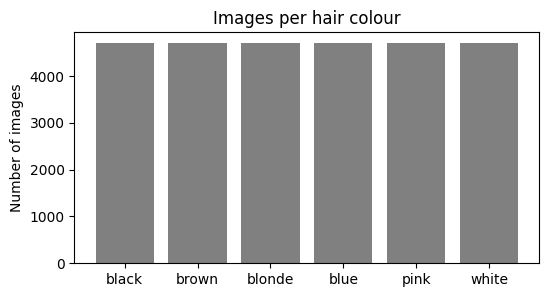

In [6]:
counts = np.bincount(labels, minlength=NUM_CLASSES)
for name, count in zip(CLASSES, counts):
    print(f"{name:7s} {count}")

plt.figure(figsize=(6, 3))
plt.bar(CLASSES, counts, color="grey")
plt.title("Images per hair colour")
plt.ylabel("Number of images")
plt.show()

## 5. Dataset class, transforms and DataLoader

### 5.1 Transforms

| Step | What it does | Why |
|---|---|---|
| `RandomHorizontalFlip(p=0.5)` | Mirrors the face left–right in half of the cases | **Data augmentation**: a mirrored face is still a face with the same hair colour, so we get more variety for free |
| `ToTensor()` | Picture → tensor, pixels 0..255 → **0..1** | PyTorch needs tensors with shape `[C, H, W]` |
| `Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))` | `(x − 0.5) / 0.5`: pixels 0..1 → **−1..1** | The Generator ends with **Tanh**, which outputs −1..1. Real and fake images must be in the **same range**, otherwise the Discriminator could tell them apart just by the numbers |

### 5.2 The Dataset class

Like `HFCifar10` in the Transfer Learning lab, our class has:

- `__len__`: the number of images,
- `__getitem__`: returns one `(image, label)` pair, with the transform applied.

In [7]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),                                    # 0..255 -> 0..1
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),   # 0..1   -> -1..1
])


class AnimeFaces(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images          # numpy array (N, 64, 64, 3)
        self.labels = labels          # numpy array (N,)
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        picture = Image.fromarray(self.images[i])
        return self.transform(picture), int(self.labels[i])


train_data = AnimeFaces(images, labels, transform)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

real_batch, real_labels = next(iter(train_loader))
print("One batch of images:", real_batch.shape)     # [128, 3, 64, 64]
print("One batch of labels:", real_labels.shape)    # [128]
print("Pixel range:", real_batch.min().item(), "to", real_batch.max().item())
print("Batches per epoch:", len(train_loader))

One batch of images: torch.Size([128, 3, 64, 64])
One batch of labels: torch.Size([128])
Pixel range: -1.0 to 1.0
Batches per epoch: 220


`drop_last=True` throws away the last, smaller batch, so every batch has exactly `BATCH_SIZE` images. This keeps BatchNorm stable.

## 6. Look at the training images

The helper `to_image` undoes the normalisation (−1..1 → 0..1) and changes the shape from `[C, H, W]` to `[H, W, C]` for matplotlib — the same idea as in the Image Classification lab.

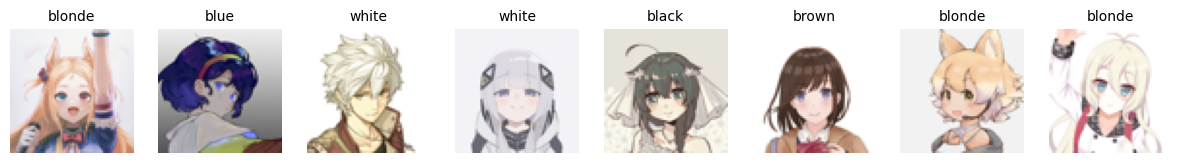

In [8]:
def to_image(tensor_image):
    img = tensor_image.detach().cpu() * 0.5 + 0.5    # undo Normalize: -1..1 -> 0..1
    img = img.clamp(0, 1).permute(1, 2, 0).numpy()   # [C, H, W] -> [H, W, C]
    return img


plt.figure(figsize=(15, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(to_image(real_batch[i]))
    plt.title(CLASSES[real_labels[i]], fontsize=10)
    plt.axis("off")
plt.show()

## 7. The Generator

**Job:** turn random noise **+ the hair colour** into a 64 x 64 colour image.

**The condition (label):** the hair colour is turned into a **one-hot vector** of length 6. For example `blue` → `[0, 0, 0, 1, 0, 0]`. We **join** (concatenate) it with the noise: 100 + 6 = **106 numbers**.

**Up-sampling** with `ConvTranspose2d`: each block makes the image **2 times bigger**.

```
noise (100) + one-hot (6) = 106 numbers, reshaped to 106 x 1 x 1
ConvTranspose(106 -> 512)  + BatchNorm + ReLU      512 x  4 x  4
ConvTranspose(512 -> 256)  + BatchNorm + ReLU      256 x  8 x  8
ConvTranspose(256 -> 128)  + BatchNorm + ReLU      128 x 16 x 16
ConvTranspose(128 -> 64)   + BatchNorm + ReLU       64 x 32 x 32
ConvTranspose(64  -> 3)    + Tanh                    3 x 64 x 64   (RGB image, pixels -1..1)
```

| Choice | Why |
|---|---|
| `ConvTranspose2d` (kernel 4, stride 2, padding 1) | Learns how to make the image 2x bigger and add detail |
| `BatchNorm2d` | Keeps values in a stable range → more stable GAN training |
| `ReLU` | Non-linearity, so the network can learn complex shapes |
| `Tanh` at the end | Outputs −1..1, the same range as our normalised real images |
| `bias=False` before BatchNorm | BatchNorm already has its own shift, so a bias would do nothing |

In [9]:
class Generator(nn.Module):
    def __init__(self, noise_dim=NOISE_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes
        in_ch = noise_dim + num_classes                                  # 100 + 6 = 106

        self.net = nn.Sequential(
            # 106 x 1 x 1  ->  512 x 4 x 4
            nn.ConvTranspose2d(in_ch, 512, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(512), nn.ReLU(),
            # 512 x 4 x 4  ->  256 x 8 x 8
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(),
            # 256 x 8 x 8  ->  128 x 16 x 16
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(),
            # 128 x 16 x 16  ->  64 x 32 x 32
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            # 64 x 32 x 32  ->  3 x 64 x 64
            nn.ConvTranspose2d(64, 3, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh(),
        )

    def forward(self, noise, labels):
        one_hot = F.one_hot(labels, self.num_classes).float()   # [batch, 6]
        x = torch.cat([noise, one_hot], dim=1)                  # [batch, 106]
        x = x.view(x.size(0), -1, 1, 1)                         # [batch, 106, 1, 1]
        return self.net(x)                                      # [batch, 3, 64, 64]

## 8. The Discriminator

**Job:** look at an image **+ the hair colour** and say how likely it is that the image is **real** and **matches** the colour.

**The condition (label):** the one-hot vector (6 numbers) is stretched into **6 extra channels** of size 64 x 64 (every pixel of channel `c` is 1 if the colour is `c`, else 0). We attach them to the RGB image: 3 + 6 = **9 channels**. Now the Discriminator sees the picture and the colour at the same time.

**Down-sampling** with `Conv2d` and **stride 2**: each block makes the image **2 times smaller** (no pooling — the network learns how to down-sample).

```
image (3) + label channels (6)                     9 x 64 x 64
Conv(9   -> 64)  + LeakyReLU                      64 x 32 x 32
Conv(64  -> 128) + BatchNorm + LeakyReLU         128 x 16 x 16
Conv(128 -> 256) + BatchNorm + LeakyReLU         256 x  8 x  8
Conv(256 -> 512) + BatchNorm + LeakyReLU         512 x  4 x  4
Conv(512 -> 1)   + Sigmoid                         1 x  1 x  1   (probability 0..1)
```

| Choice | Why |
|---|---|
| `Conv2d` with stride 2 | Halves the size each time: 64 → 32 → 16 → 8 → 4 |
| `LeakyReLU(0.2)` | Negative values become 0.2·x instead of 0 → **no dead neurons**, so gradients can flow back to the Generator |
| No BatchNorm in the first block | Recommended by the DCGAN paper: keeps the original colour information of the input |
| `Sigmoid` at the end | One number between 0 (fake) and 1 (real) |

In [10]:
class Discriminator(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.num_classes = num_classes

        self.net = nn.Sequential(
            # 9 x 64 x 64  ->  64 x 32 x 32
            nn.Conv2d(3 + num_classes, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2),
            # 64 x 32 x 32  ->  128 x 16 x 16
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            # 128 x 16 x 16  ->  256 x 8 x 8
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2),
            # 256 x 8 x 8  ->  512 x 4 x 4
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512), nn.LeakyReLU(0.2),
            # 512 x 4 x 4  ->  1 x 1 x 1
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, images, labels):
        one_hot = F.one_hot(labels, self.num_classes).float()               # [batch, 6]
        label_maps = one_hot.view(-1, self.num_classes, 1, 1)               # [batch, 6, 1, 1]
        label_maps = label_maps.expand(-1, -1, images.size(2), images.size(3))  # [batch, 6, 64, 64]
        x = torch.cat([images, label_maps], dim=1)                          # [batch, 9, 64, 64]
        return self.net(x).view(-1)                                         # [batch]

## 9. Check shapes and parameters

### 9.1 Weight initialisation

The DCGAN paper starts all weights from small random numbers (normal distribution, mean 0, standard deviation **0.02**). This gives both networks a calm, equal start. `model.apply(fn)` runs `fn` on every layer.

### 9.2 Shape check

Like in the labs, we check the shapes **before** training. It saves a lot of time.

In [11]:
def init_weights(layer):
    if isinstance(layer, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(layer.weight, 0.0, 0.02)
    elif isinstance(layer, nn.BatchNorm2d):
        nn.init.normal_(layer.weight, 1.0, 0.02)
        nn.init.zeros_(layer.bias)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


set_seed(42)
G = Generator().to(device)
D = Discriminator().to(device)
G.apply(init_weights)
D.apply(init_weights)

noise = torch.randn(4, NOISE_DIM, device=device)
some_labels = torch.tensor([0, 1, 2, 3], device=device)

fake = G(noise, some_labels)
score = D(fake, some_labels)
print("Noise shape:        ", noise.shape)    # [4, 100]
print("Generator output:   ", fake.shape)     # [4, 3, 64, 64]
print("Discriminator output:", score.shape)   # [4]
print("Discriminator scores:", score.detach().cpu().numpy().round(3))   # random guesses before training
print()
print("Generator parameters:    ", count_parameters(G))
print("Discriminator parameters:", count_parameters(D))

Noise shape:         torch.Size([4, 100])
Generator output:    torch.Size([4, 3, 64, 64])
Discriminator output: torch.Size([4])
Discriminator scores: [0.257 0.219 0.516 0.244]

Generator parameters:     3625856
Discriminator parameters: 2771712


Before training, the Discriminator's scores are just **random guesses** (somewhere between 0 and 1): its weights are random and it knows nothing yet.

## 10. Loss function and optimizers

### Loss: Binary Cross-Entropy (`BCELoss`)

The Discriminator answers a **yes/no** question (real or fake?), so we use **binary** cross-entropy. It compares the Discriminator's probability with a target:

- target **1** = "this should be called real"
- target **0** = "this should be called fake"

The loss is small when the probability is close to the target, and large when it is far away.

| Network | Input | Target we give | Meaning |
|---|---|---|---|
| D, real images | real image + its label | **1** | "say REAL for real images" |
| D, fake images | fake image + its label | **0** | "say FAKE for fake images" |
| G | fake image + its label | **1** | G wants D to **believe** its fake is real |

### Optimizers

Each network has **its own** Adam optimizer, because they are trained separately. We use `lr = 0.0002` and `betas = (0.5, 0.999)`, the values from the DCGAN paper.

In [12]:
loss_fn = nn.BCELoss()

optimizer_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(BETA1, 0.999))

## 11. The training loop

For every batch we do **two steps**, in turns (alternating training).

**Step 1 — train the Discriminator (the Generator does not change):**

1. Generate fake images from noise + labels.
2. `.detach()` the fake images: no gradients flow into G, so **G is frozen** in this step.
3. Loss = BCE(D(real), 1) + BCE(D(fake), 0).
4. Backward pass, then `optimizer_D.step()` updates **only D**.

**Step 2 — train the Generator (the Discriminator does not change):**

1. Show the **same** fake images to D again (D has just been updated).
2. Loss = BCE(D(fake), **1**): G is rewarded when D is fooled.
3. Backward pass, then `optimizer_G.step()` updates **only G**. D's weights are not stepped, so **D is frozen** in this step.

Inside each step you can see the same **five steps** as in every lab: zero_grad → forward → loss → backward → step.

**What we record after every epoch** (in `history`):

| Value | Meaning |
|---|---|
| `loss_D`, `loss_G` | The average loss of each network |
| `D_real` | Average D output on real images (D wants this close to 1) |
| `D_fake` | Average D output on fake images (D wants 0, G wants 1). When G gets good, both move towards **0.5** (Nash equilibrium) |

**Fixed noise:** we keep the same noise vectors for the whole training and draw them after every epoch. This way we see how the **same** "seeds" turn from noise into faces.

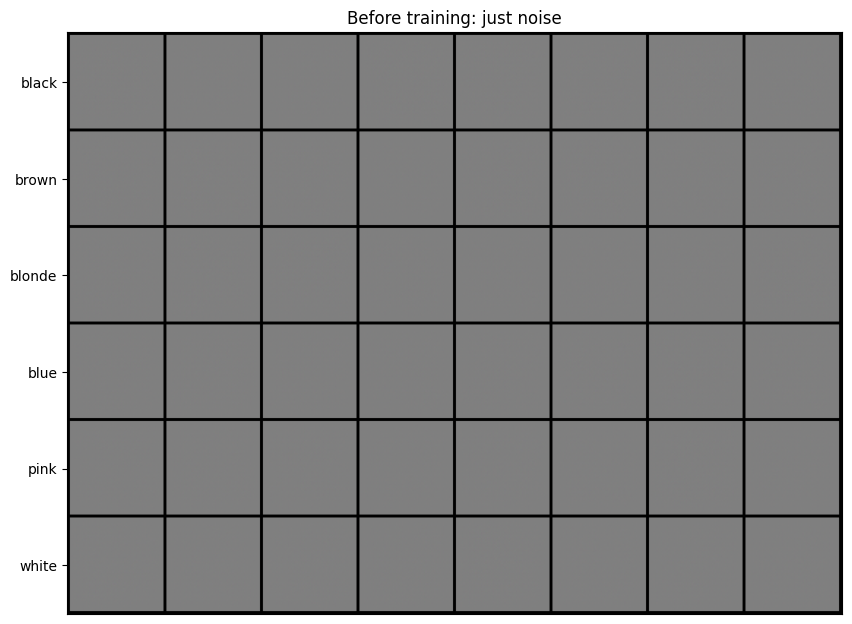

In [13]:
# Fixed noise: 8 faces for each of the 6 colours (48 images)
set_seed(0)
fixed_noise = torch.randn(8 * NUM_CLASSES, NOISE_DIM, device=device)
fixed_labels = torch.arange(NUM_CLASSES, device=device).repeat_interleave(8)   # 0,0,...,1,1,...


def show_samples(G, title=""):
    G.eval()
    with torch.no_grad():
        fake = G(fixed_noise, fixed_labels).cpu()
    G.train()
    grid = make_grid(fake, nrow=8, normalize=True, value_range=(-1, 1))   # one row per colour
    plt.figure(figsize=(10, 8))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.yticks([34 + 66 * i for i in range(NUM_CLASSES)], CLASSES)
    plt.xticks([])
    plt.title(title)
    plt.show()


show_samples(G, "Before training: just noise")

In [14]:
def train_gan(G, D, loader, epochs, checkpoint_path=None):
    history = {"loss_D": [], "loss_G": [], "D_real": [], "D_fake": []}

    for epoch in range(epochs):
        start = time.time()
        sum_loss_D, sum_loss_G, sum_real, sum_fake = 0, 0, 0, 0

        for real_images, labels in loader:
            real_images, labels = real_images.to(device), labels.to(device)
            batch = real_images.size(0)
            ones = torch.ones(batch, device=device)     # target "real"
            zeros = torch.zeros(batch, device=device)   # target "fake"

            noise = torch.randn(batch, NOISE_DIM, device=device)
            fake_images = G(noise, labels)              # G draws faces with the SAME colours as the real batch

            # ---------- Step 1: train the Discriminator (G frozen) ----------
            optimizer_D.zero_grad()                                   # 1. clear old gradients
            d_real = D(real_images, labels)                           # 2. forward pass: real
            d_fake = D(fake_images.detach(), labels)                  #    forward pass: fake (detach = G frozen)
            loss_D = loss_fn(d_real, ones) + loss_fn(d_fake, zeros)   # 3. compute loss
            loss_D.backward()                                         # 4. compute gradients
            optimizer_D.step()                                        # 5. update D only

            # ---------- Step 2: train the Generator (D frozen) ----------
            optimizer_G.zero_grad()                                   # 1. clear old gradients
            d_fake_for_G = D(fake_images, labels)                     # 2. forward pass through the updated D
            loss_G = loss_fn(d_fake_for_G, ones)                      # 3. G wants D to say "real" (1)
            loss_G.backward()                                         # 4. compute gradients
            optimizer_G.step()                                        # 5. update G only

            sum_loss_D += loss_D.item()
            sum_loss_G += loss_G.item()
            sum_real += d_real.mean().item()
            sum_fake += d_fake.mean().item()

        n = len(loader)
        history["loss_D"].append(sum_loss_D / n)
        history["loss_G"].append(sum_loss_G / n)
        history["D_real"].append(sum_real / n)
        history["D_fake"].append(sum_fake / n)

        print(f"Epoch {epoch + 1:2d}/{epochs} | loss D {sum_loss_D / n:.3f} | loss G {sum_loss_G / n:.3f} | "
              f"D(real) {sum_real / n:.2f} | D(fake) {sum_fake / n:.2f} | {time.time() - start:.0f}s")

        if checkpoint_path is not None:                               # save after every epoch
            torch.save(G.state_dict(), checkpoint_path)
        if (epoch + 1) % 5 == 0 or epoch == 0:
            show_samples(G, f"After epoch {epoch + 1}")

    return history

In [15]:
set_seed(42)
history = train_gan(G, D, train_loader, EPOCHS,
                    checkpoint_path=os.path.join(SAVE_DIR, "generator_checkpoint.pt"))

KeyboardInterrupt: 

## 12. Loss curves

**GAN curves look different from the curves in the other labs!** In a classifier, the loss simply goes down. In a GAN the two networks **compete**, so:

- the losses do **not** go to 0; they go up and down and then stay in a range,
- if `loss_D` goes to almost **0** and `loss_G` keeps growing, D has won completely and G can't learn anymore,
- `D(real)` and `D(fake)` should move **towards each other**. In theory, at the perfect end point (Nash equilibrium) both are **0.5**.

So for a GAN, the most important "evaluation" is **looking at the generated images** (Section 13).

In [ ]:
epochs_range = range(1, len(history["loss_D"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["loss_D"], marker="o", label="Discriminator")
plt.plot(epochs_range, history["loss_G"], marker="o", label="Generator")
plt.xlabel("Epoch")
plt.ylabel("Average BCE loss")
plt.title("Losses")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["D_real"], marker="o", label="D(real)")
plt.plot(epochs_range, history["D_fake"], marker="o", label="D(fake)")
plt.axhline(0.5, color="black", linestyle="--", label="0.5 (Nash equilibrium)")
plt.xlabel("Epoch")
plt.ylabel("Average D output")
plt.title("Discriminator outputs")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)

plt.show()

## 13. Generate faces for every hair colour

After training we **only need the Generator** (the Discriminator was only the "teacher").

`generate(colour, n)` makes `n` new faces with the chosen hair colour:

1. make `n` random noise vectors,
2. make `n` labels with the chosen colour,
3. pass them through G (`eval()` mode, `no_grad()`).

**What to check:**

1. **Quality:** do the images look like anime faces?
2. **Condition:** does the hair colour match the label in every row?
3. **Variety:** are the faces in one row different from each other? If they all look the same, this is **mode collapse**.

In [ ]:
show_samples(G, f"After training ({EPOCHS} epochs): one row per hair colour")

In [ ]:
def generate(G, colour, n=8):
    G.eval()
    label = CLASSES.index(colour)
    noise = torch.randn(n, NOISE_DIM, device=device)
    labels = torch.full((n,), label, dtype=torch.long, device=device)
    with torch.no_grad():
        fake = G(noise, labels).cpu()
    return fake


colour = "pink"      # try: black, brown, blonde, blue, pink, white
faces = generate(G, colour, n=8)

plt.figure(figsize=(15, 2.5))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(to_image(faces[i]))
    plt.axis("off")
plt.suptitle(f"New faces with {colour} hair")
plt.show()

### 13.1 Same noise, different colour

Now we keep **one** noise vector and change **only the label**. If the condition works well, the face should stay similar, and only the hair colour should change. This shows that the label really **controls** the hair colour.

In [ ]:
G.eval()
set_seed(7)
one_noise = torch.randn(1, NOISE_DIM, device=device).repeat(NUM_CLASSES, 1)   # the same noise 6 times
all_labels = torch.arange(NUM_CLASSES, device=device)                         # 0, 1, 2, 3, 4, 5
with torch.no_grad():
    faces = G(one_noise, all_labels).cpu()

plt.figure(figsize=(12, 2.5))
for i in range(NUM_CLASSES):
    plt.subplot(1, NUM_CLASSES, i + 1)
    plt.imshow(to_image(faces[i]))
    plt.title(CLASSES[i])
    plt.axis("off")
plt.suptitle("Same noise, only the hair-colour label changes")
plt.show()

## 14. Save the model

We save the **Generator's weights** (`state_dict`) and the settings needed to rebuild it. We will load this file later for **deployment** (a local API that returns a face for a chosen colour).

In [ ]:
MODEL_FILE = os.path.join(SAVE_DIR, "anime_cdcgan_generator.pt")
torch.save({
    "generator": G.state_dict(),
    "classes": CLASSES,
    "noise_dim": NOISE_DIM,
    "img_size": IMG_SIZE,
}, MODEL_FILE)
pd.DataFrame(history).to_csv(os.path.join(SAVE_DIR, "history.csv"), index=False)
print("Saved:", MODEL_FILE)

**How to load it again** (for example in a new notebook or in the API):

```python
checkpoint = torch.load("anime_cdcgan_generator.pt", map_location="cpu")
G = Generator(noise_dim=checkpoint["noise_dim"], num_classes=len(checkpoint["classes"]))
G.load_state_dict(checkpoint["generator"])
G.eval()
```

## 15. Summary

| Part | Key point |
|---|---|
| Data | Danbooru face crops, rating `g`, exactly one hair colour, 6 colours × 4700 images (balanced), resized to 64 × 64 |
| Normalisation | Pixels → −1..1, the same range as the Generator's Tanh output |
| Condition | Hair colour as a **one-hot** vector: joined to the noise in G, added as 6 extra channels in D |
| Generator | Noise + label → `ConvTranspose2d` blocks (BatchNorm + ReLU) → Tanh → 3 × 64 × 64 |
| Discriminator | Image + label → `Conv2d` stride 2 blocks (LeakyReLU) → Sigmoid → probability |
| Loss | Binary cross-entropy. D: real → 1, fake → 0. G: fake → 1 (fool D) |
| Training | Alternating: step 1 updates D (G frozen with `.detach()`), step 2 updates G (D not stepped) |
| Optimizer | Adam, lr = 0.0002, β1 = 0.5 (DCGAN paper) |
| Evaluation | Look at the samples: quality, correct hair colour, variety (no mode collapse) |
| After training | Keep only G; save its weights for deployment |